# Bank Marketing: EDA and Term Deposit Prediction

**Dataset:** UCI Bank Marketing (`bank-full.csv`)  
**Goal:** predict whether a client subscribes to a term deposit (`y`).

`duration` (last call length) is used in the EDA but **excluded from the models**, because it is only known after the call and would leak the outcome.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


## 2. Dataset description

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

print(f"Rows: {df.shape[0]:,} | Input features: {df.shape[1] - 1} | Target: y")
display(df.head())
df.info()
display(df.describe().T)
print("Missing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())

categorical_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()
numeric_cols = df.select_dtypes(include="number").columns.tolist()
display((df[categorical_cols] == "unknown").sum().loc[lambda s: s > 0].rename("unknown_count").to_frame())

Rows: 45,211 | Input features: 16 | Target: y


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


Missing values: 0 | Duplicate rows: 0


,unknown_count
job,288
education,1857
contact,13020
poutcome,36959


**Interpretation.**
- 45,211 clients, 16 input features (7 numeric, 9 categorical) and a binary target `y`.
- No missing values and no duplicates.
- Missing information is hidden as the text `unknown` (mostly in `contact` and `poutcome`), and `pdays = -1` means "never contacted before". These are handled in preprocessing.

## 3. Exploratory data analysis

### 3.1 Class distribution

,count,percent
y,,
no,39922,88.3
yes,5289,11.7


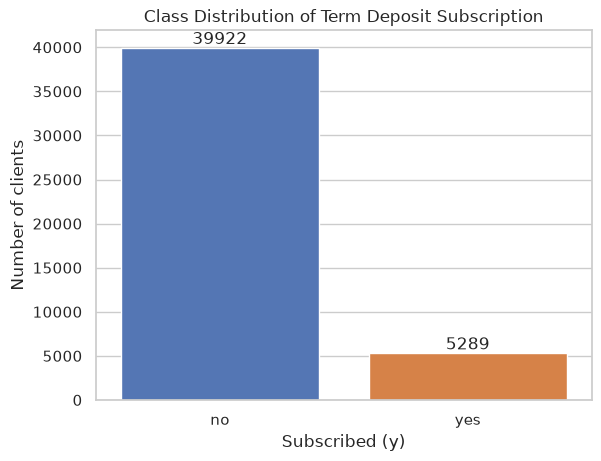

In [3]:
counts = df["y"].value_counts()
display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))

ax = sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", palette=["#4472C4", "#ED7D31"], legend=False)
ax.bar_label(ax.containers[0], fmt="%d")
ax.bar_label(ax.containers[1], fmt="%d")
ax.set(title="Class Distribution of Term Deposit Subscription", xlabel="Subscribed (y)", ylabel="Number of clients")
plt.show()


**Interpretation.** Only about 11.7% of clients subscribed, so the data is strongly imbalanced. A model that always predicts "no" would be 88% accurate, so accuracy is misleading. We focus on recall, precision, F1, ROC-AUC and PR-AUC, and use class weights when training.

### 3.2 Numeric features vs target

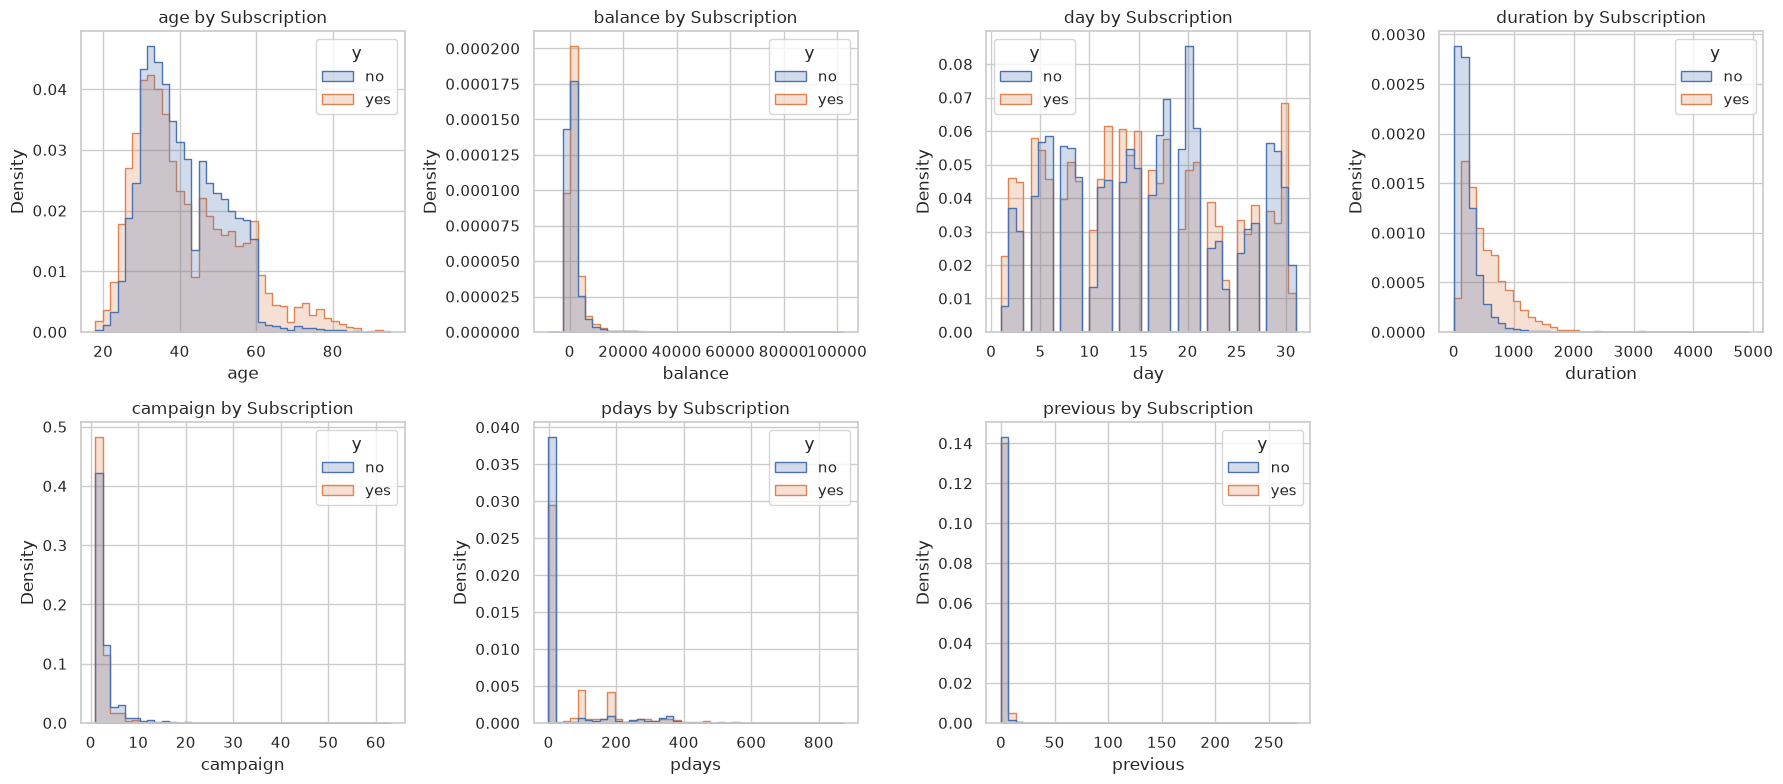

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for col, ax in zip(numeric_cols, axes.flat):
    sns.histplot(data=df, x=col, hue="y", bins=40, stat="density", common_norm=False, element="step", ax=ax)
    ax.set(title=f"{col} by Subscription", xlabel=col, ylabel="Density")
axes.flat[-1].remove()
plt.tight_layout()
plt.show()


**Interpretation.**
- `duration` separates the classes best (subscribers have longer calls), but it is only known after the call, so we do not use it for modelling.
- `balance`, `campaign`, `pdays` and `previous` are strongly right-skewed with extreme values.
- `age` and `day` look similar for both classes.

### 3.3 Outliers

,outliers (IQR rule),percent
age,487,1.1
balance,4729,10.5
day,0,0.0
duration,3235,7.2
campaign,3064,6.8
pdays,8257,18.3
previous,8257,18.3


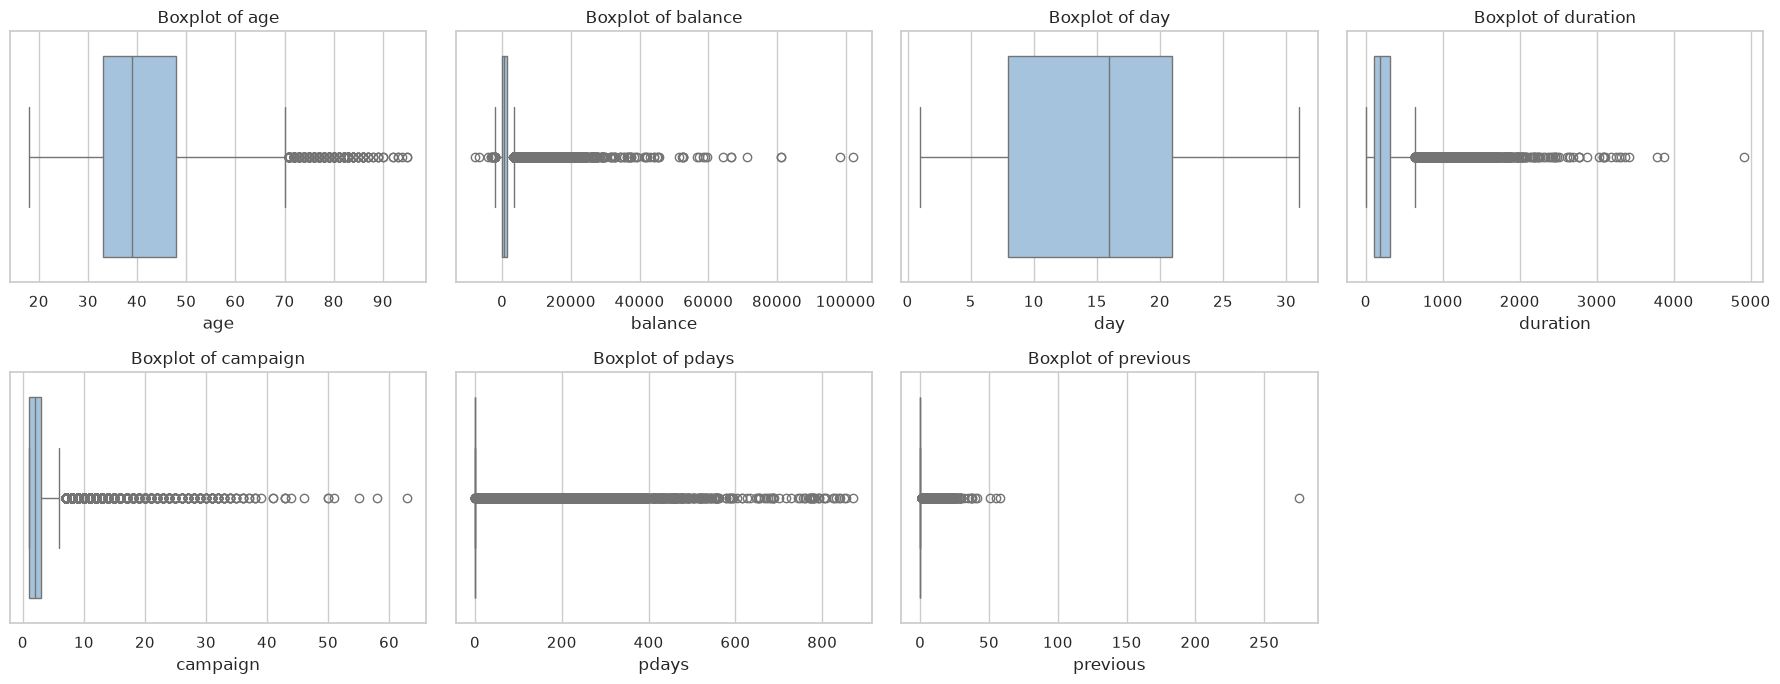

In [5]:
q1, q3 = df[numeric_cols].quantile(0.25), df[numeric_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numeric_cols] < q1 - 1.5 * iqr) | (df[numeric_cols] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({"outliers (IQR rule)": outliers, "percent": (outliers / len(df) * 100).round(1)}))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, ax in zip(numeric_cols, axes.flat):
    sns.boxplot(data=df, x=col, ax=ax, color="#9DC3E6")
    ax.set(title=f"Boxplot of {col}", xlabel=col)
axes.flat[-1].remove()
plt.tight_layout()
plt.show()


**Interpretation.** `balance`, `campaign`, `previous` and `duration` have many outliers, but they are real values (e.g. a large bank balance), not errors. We keep them and reduce their effect with a log transform instead of deleting rows.

### 3.4 Categorical features vs target

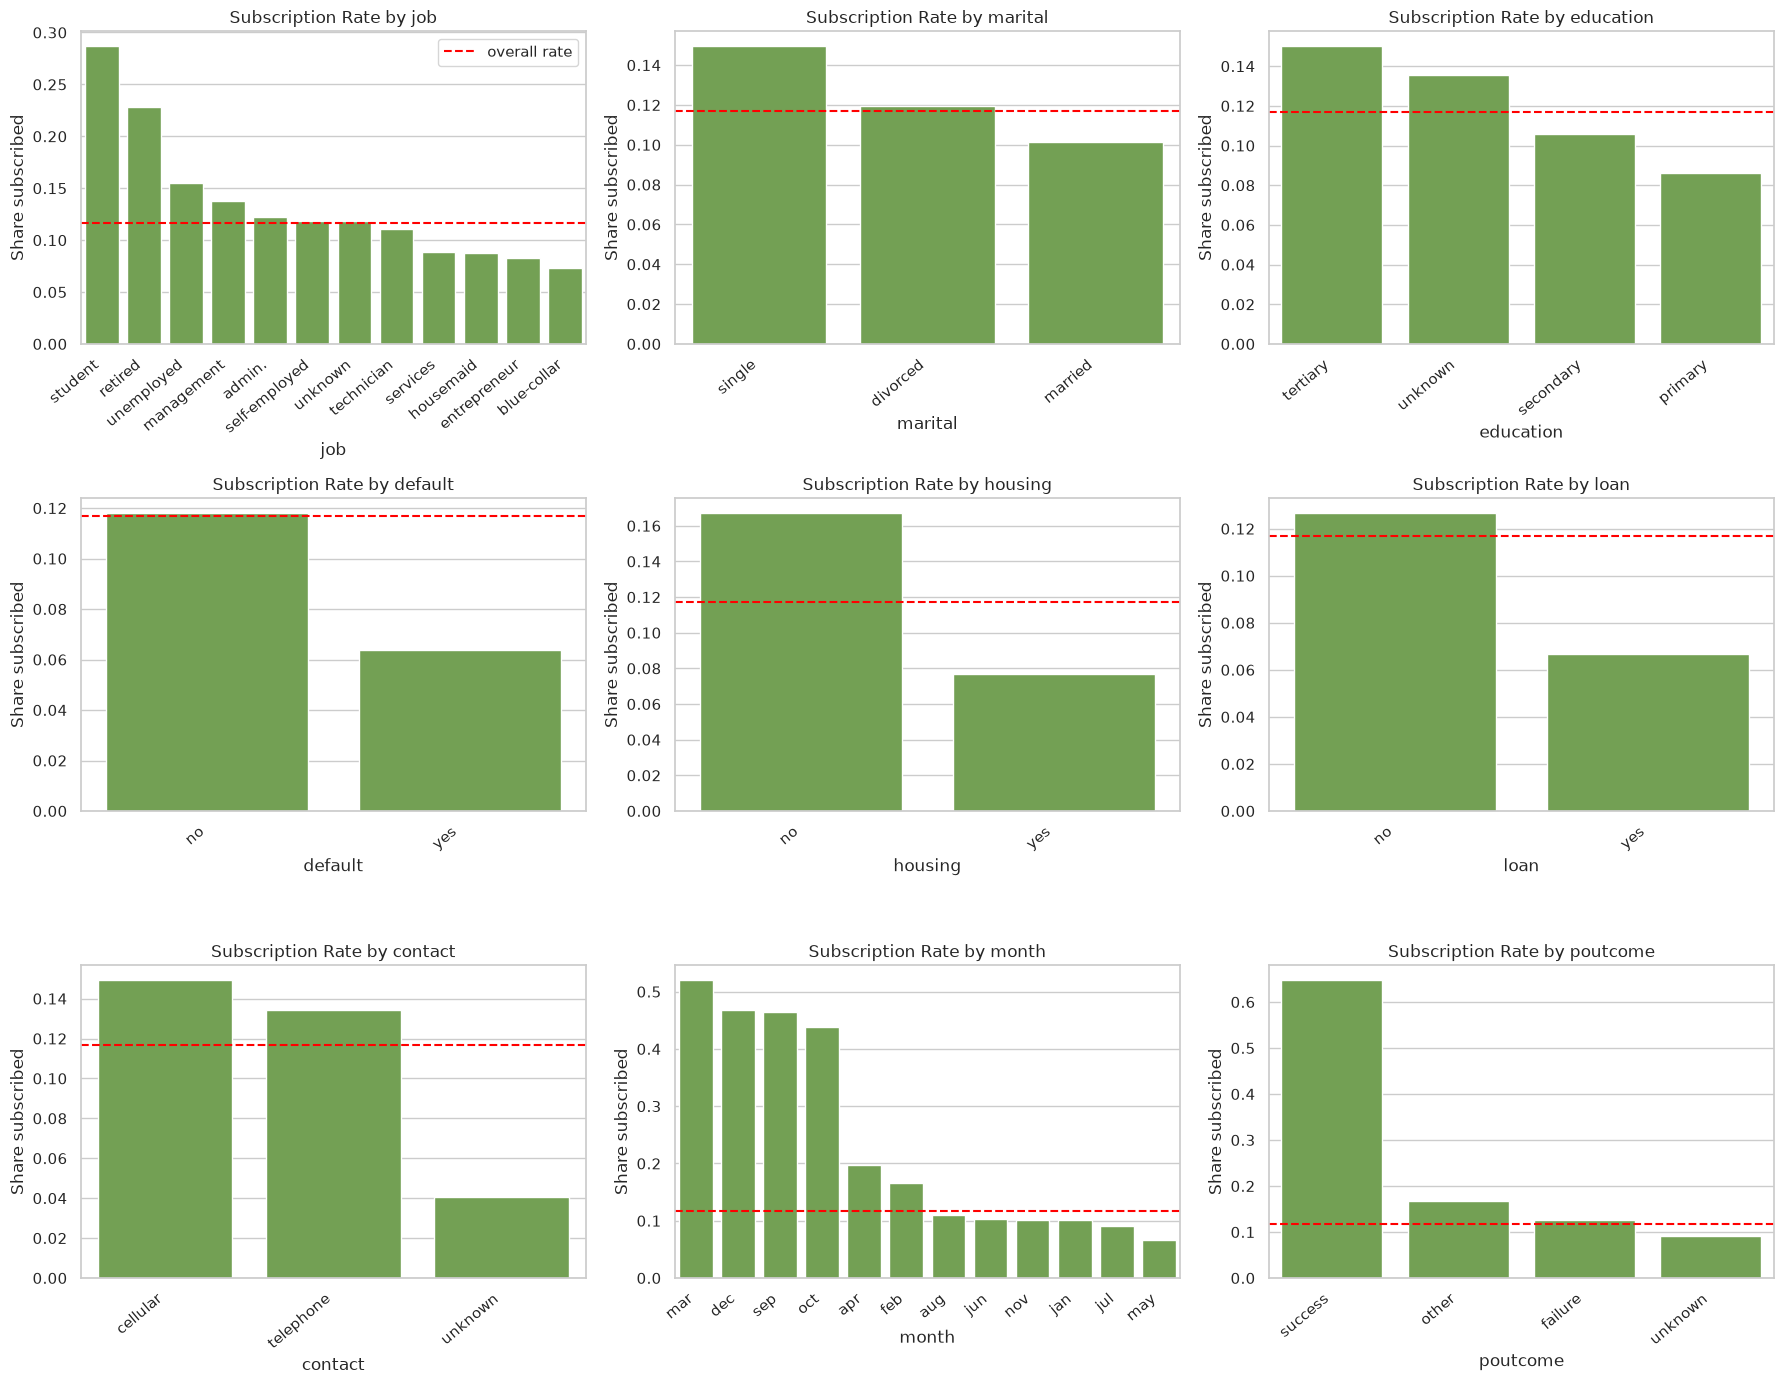

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for col, ax in zip(categorical_cols, axes.flat):
    rates = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="#70AD47")
    ax.axhline((df["y"] == "yes").mean(), color="red", linestyle="--", label="overall rate")
    ax.set(title=f"Subscription Rate by {col}", xlabel=col, ylabel="Share subscribed")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
axes[0, 0].legend()
plt.tight_layout()
plt.show()


**Interpretation.**
- Previous campaign success (`poutcome = success`) gives by far the highest rate (about 65%).
- Students and retired clients, tertiary education, and singles subscribe more often.
- Clients without a housing or personal loan subscribe more often.
- Rates are highest in March, September, October and December, but those months have few contacts; May has the most contacts and the lowest rate.

### 3.5 Correlation heatmap

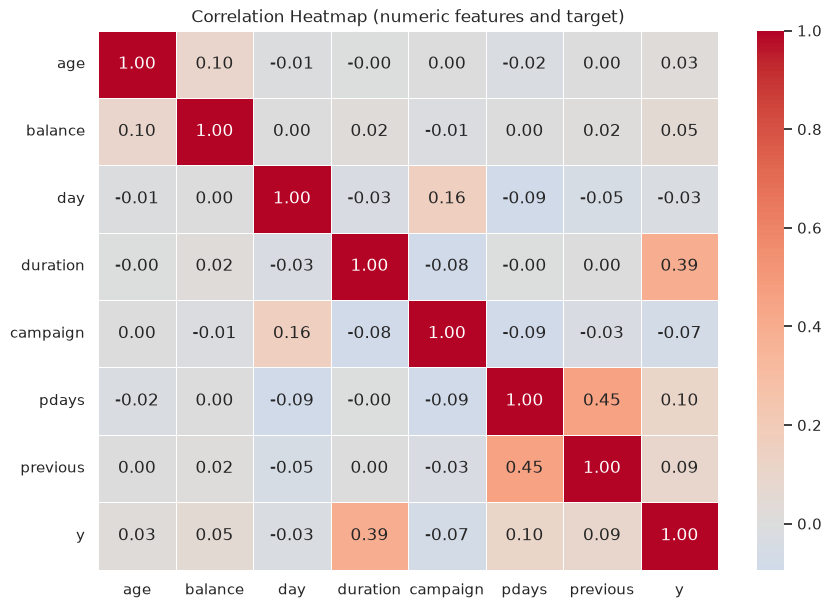

In [7]:
corr_df = df[numeric_cols].assign(y=(df["y"] == "yes").astype(int))

plt.figure(figsize=(10, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4)
plt.title("Correlation Heatmap (numeric features and target)")
plt.show()


**Interpretation.** `duration` has the strongest correlation with the target (0.39, excluded from modelling). All other correlations with the target are weak (below 0.11 in absolute value).

## 4. Preprocessing

Steps used:
1. Treat `unknown` in `job` and `education` as missing values (few rows). Keep `unknown` as its own category in `contact` and `poutcome` (large share, probably informative).
2. Feature engineering: `previously_contacted` flag from `pdays`; then `pdays = -1` becomes 0.
3. Drop `duration` (data leakage).
4. Stratified 80/20 train/test split, done **before** fitting any transformer.
5. Inside a pipeline: median/mode imputation, signed log transform for skewed features, standard scaling, ordinal encoding for `education`, one-hot encoding for other categorical features.
6. Class imbalance handled with class weights in the models.

In [8]:
data = df.copy()
data[["job", "education"]] = data[["job", "education"]].replace("unknown", np.nan)
data["previously_contacted"] = (data["pdays"] != -1).astype(int)
data["pdays"] = data["pdays"].replace(-1, 0)

X = data.drop(columns=["y", "duration"])
y = (data["y"] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Subscription rate - train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")
print("Missing values in train:", X_train.isna().sum()[lambda s: s > 0].to_dict())

Train: (36168, 16) | Test: (9043, 16)
Subscription rate - train: 0.117 | test: 0.117
Missing values in train: {'job': 234, 'education': 1482}


**Interpretation.** The split keeps the same subscription rate (about 11.7%) in train and test. `job` and `education` now contain missing values, which are imputed inside the pipeline using training data only.

Features after preprocessing: 44
Missing values after preprocessing: 0


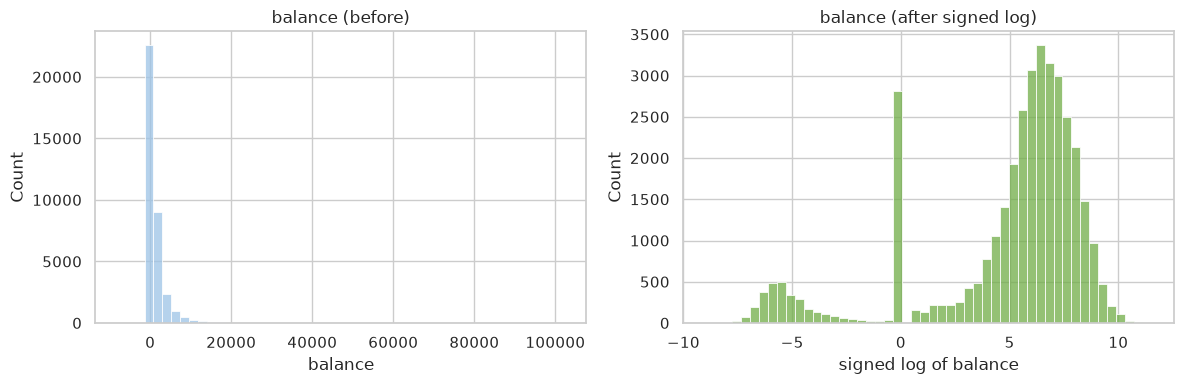

In [9]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

log_features = ["balance", "campaign", "pdays", "previous"]
scale_features = ["age", "day"]
flag_features = ["previously_contacted"]
ordinal_features = ["education"]
nominal_features = ["job", "marital", "default", "housing", "loan", "contact", "month", "poutcome"]

preprocessor = ColumnTransformer([
    ("log", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(signed_log)),
        ("scaler", StandardScaler()),
    ]), log_features),
    ("scale", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), scale_features),
    ("ordinal", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=[["primary", "secondary", "tertiary"]])),
        ("scaler", StandardScaler()),
    ]), ordinal_features),
    ("nominal", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
    ]), nominal_features),
    ("flag", "passthrough", flag_features),
], sparse_threshold=0)

X_train_prepared = preprocessor.fit_transform(X_train)
print("Features after preprocessing:", X_train_prepared.shape[1])
print("Missing values after preprocessing:", int(np.isnan(X_train_prepared).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X_train["balance"], bins=50, ax=axes[0], color="#9DC3E6")
axes[0].set(title="balance (before)", xlabel="balance", ylabel="Count")
sns.histplot(signed_log(X_train["balance"]), bins=50, ax=axes[1], color="#70AD47")
axes[1].set(title="balance (after signed log)", xlabel="signed log of balance", ylabel="Count")
plt.tight_layout()
plt.show()


**Interpretation.** The transform removes most of the skew and outlier effect without deleting rows. Preprocessing produces a fully numeric matrix with no missing values, ready for all models.

## 5. Model training


In [10]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

classifiers = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="logloss", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "SVM (linear)": LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
}

models = {name: Pipeline([("preprocess", preprocessor), ("model", clf)]) for name, clf in classifiers.items()}
for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost
Trained: KNN
Trained: SVM (linear)


**Interpretation.** All six models are trained on the same training set. `class_weight` and `scale_pos_weight` make errors on the rare "yes" class cost more, which increases recall.

## 6. Evaluation on the test set

In [11]:
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

scores = {name: get_scores(model, X_test) for name, model in models.items()}
preds = {name: model.predict(X_test) for name, model in models.items()}

results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, scores[name]),
        "PR-AUC": average_precision_score(y_test, scores[name]),
    } for name in models
}).T.sort_values("PR-AUC", ascending=False)

display(results.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.818,0.349,0.647,0.454,0.805,0.470
Random Forest,0.867,0.444,0.535,0.485,0.806,0.455
Logistic Regression,0.755,0.270,0.643,0.380,0.772,0.413
SVM (linear),0.757,0.272,0.639,0.381,0.772,0.409
KNN,0.892,0.672,0.149,0.244,0.754,0.379
Decision Tree,0.823,0.343,0.558,0.425,0.757,0.355


**Interpretation.** Precision, recall and F1 are for the "yes" class. ROC-AUC and PR-AUC measure how well a model ranks clients, independent of the threshold. PR-AUC is the most informative here because of the imbalance (a random model scores about 0.12). Accuracy alone is not used to compare models.

### 6.1 Confusion matrices

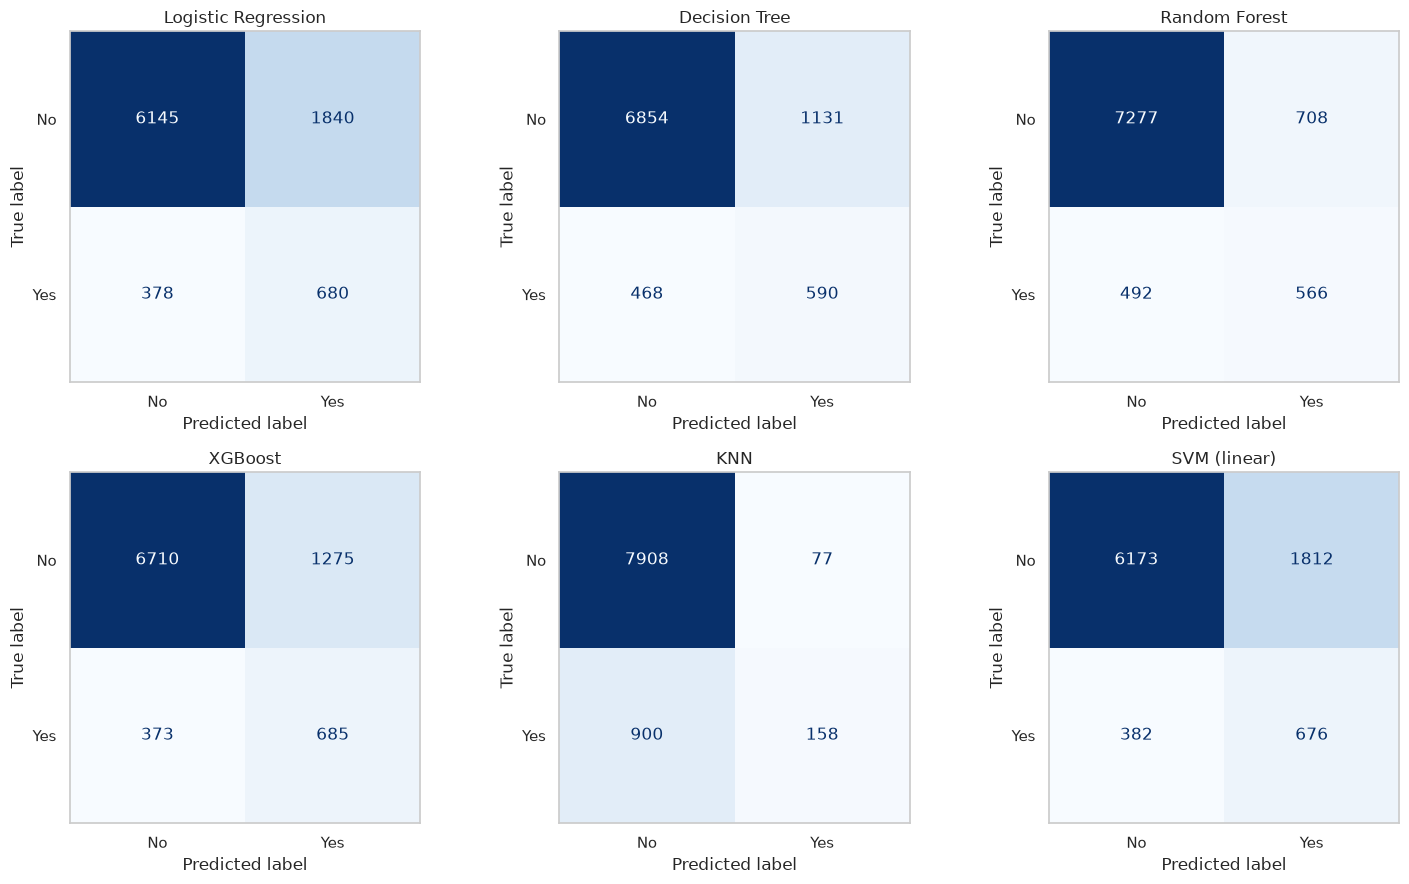

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for (name, pred), ax in zip(preds.items(), axes.flat):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No", "Yes"], cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=f"{name}", xlabel="Predicted label", ylabel="True label")
    ax.grid(False)
plt.tight_layout()
plt.show()


**Interpretation.** Models with class weights find many more subscribers (higher recall) but also contact more non-subscribers (more false positives). KNN, without class weights, misses most subscribers.

### 6.2 ROC and Precision-Recall curves

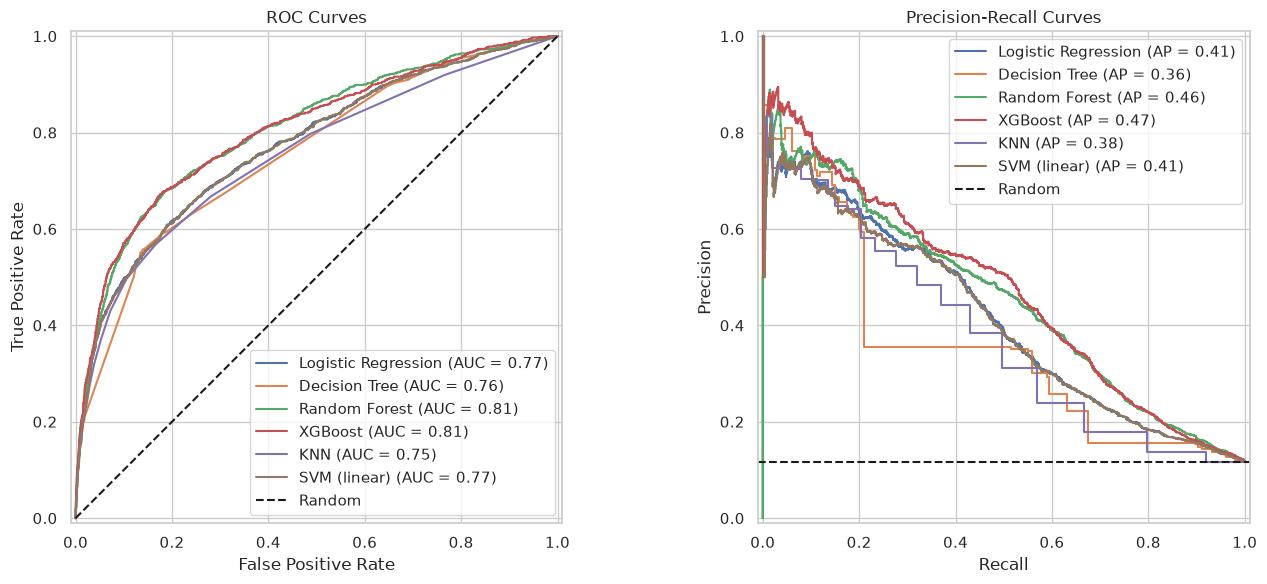

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, s in scores.items():
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set(title="ROC Curves", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Random")
axes[1].set(title="Precision-Recall Curves", xlabel="Recall", ylabel="Precision")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()


**Interpretation.** Curves closer to the top-left (ROC) and top-right (PR) are better. Boosting and ensemble models rank clients best, and all models clearly beat the random baseline. Precision falls quickly as recall grows, so reaching more subscribers means contacting many more non-subscribers.

### 6.3 Cross-validation check

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for name, model in models.items():
    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring={"F1": "f1", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision"})
    cv_rows[name] = {f"{m} mean": cv_scores[f"test_{m}"].mean() for m in ["F1", "ROC-AUC", "PR-AUC"]}
    cv_rows[name].update({f"{m} std": cv_scores[f"test_{m}"].std() for m in ["F1", "ROC-AUC", "PR-AUC"]})

display(pd.DataFrame(cv_rows).T.sort_values("PR-AUC mean", ascending=False).round(3))

,F1 mean,ROC-AUC mean,PR-AUC mean,F1 std,ROC-AUC std,PR-AUC std
XGBoost,0.446,0.800,0.448,0.011,0.002,0.012
Random Forest,0.474,0.795,0.443,0.008,0.004,0.016
Logistic Regression,0.375,0.767,0.403,0.006,0.003,0.006
SVM (linear),0.377,0.766,0.398,0.007,0.003,0.006
KNN,0.240,0.750,0.369,0.011,0.007,0.016
Decision Tree,0.405,0.748,0.347,0.009,0.002,0.007


**Interpretation.** 5-fold stratified cross-validation on the training data gives similar scores to the test set with small standard deviations. This shows the results are stable and not caused by one lucky split.

## 7. Discussion and summary of insights

In [15]:
best = results.index[0]
print(f"Best model by test PR-AUC: {best}")
display(results.loc[[best]].round(3))

Best model by test PR-AUC: XGBoost


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.818,0.349,0.647,0.454,0.805,0.47


**Results.**
- The best models by PR-AUC and ROC-AUC are XGBoost and Random Forest; see the table in section 6 for exact values. Logistic Regression and the linear SVM are close behind, while KNN and the Decision Tree are weakest.
- With class weights, recall for subscribers is high but precision is low. This is the cost of the imbalance: finding more subscribers means calling many more non-subscribers.
- Decision Tree is simple and easy to explain but ranks clients worse than the ensembles.

**Insights about the data.**
- Only about 12% of clients subscribe, so accuracy is a poor metric.
- Among the strongest signals are previous campaign success and month of contact. Students, retired clients and clients without loans subscribe more often.
- Call `duration` is the strongest single feature, but it is not available before the call, so using it would be data leakage.

**Limitations and next steps.**
- The default threshold was used. The threshold can be tuned using the PR curve and the real cost of a call versus the value of a subscription.
- Hyperparameters were set by hand; a grid or random search could improve the results.
- Results show associations in this dataset, not causes.